In [138]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
print(df.shape)

(10000, 14)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [8]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [9]:
df['Gender'].value_counts()


Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [10]:
df.drop(columns=['RowNumber','CustomerId','Surname'], inplace=True)

In [11]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [12]:
df=pd.get_dummies(df, columns=['Geography','Gender'], drop_first= True, dtype= int)

In [13]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [14]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
X_train_scaled

array([[ 0.35649971, -0.6557859 ,  0.34567966, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.20389777,  0.29493847, -0.3483691 , ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.96147213, -1.41636539, -0.69539349, ..., -0.57946723,
         1.73494238,  0.91324755],
       ...,
       [ 0.86500853, -0.08535128, -1.38944225, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.15932282,  0.3900109 ,  1.03972843, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [ 0.47065475,  1.15059039, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]], shape=(8000, 11))

In [18]:
X_test_scaled

array([[-0.57749609, -0.6557859 , -0.69539349, ...,  1.72572313,
        -0.57638802,  0.91324755],
       [-0.29729735,  0.3900109 , -1.38944225, ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.52560743,  0.48508334, -0.3483691 , ..., -0.57946723,
         1.73494238, -1.09499335],
       ...,
       [ 0.81311987,  0.77030065,  0.69270405, ..., -0.57946723,
        -0.57638802, -1.09499335],
       [ 0.41876609, -0.94100321, -0.3483691 , ..., -0.57946723,
        -0.57638802,  0.91324755],
       [-0.24540869,  0.00972116, -1.38944225, ...,  1.72572313,
        -0.57638802,  0.91324755]], shape=(2000, 11))

In [19]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [130]:
model = Sequential()
model.add(Dense(32, activation='relu', input_dim=11))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])



c:\Users\DELL\anaconda3\envs\statistic\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [131]:
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_28 (Dense)                │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7906 - loss: 0.5005 - val_accuracy: 0.8175 - val_loss: 0.4379
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8231 - loss: 0.4248 - val_accuracy: 0.8319 - val_loss: 0.4074
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8448 - loss: 0.3915 - val_accuracy: 0.8500 - val_loss: 0.3768
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8548 - loss: 0.3658 - val_accuracy: 0.8487 - val_loss: 0.3631
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8567 - loss: 0.3527 - val_accuracy: 0.8556 - val_loss: 0.3566
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8605 - loss: 0.3443 - val_accuracy: 0.8562 - val_loss: 0.3512
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8612 - loss: 0.3392 - val_accuracy: 0.8531 - val_loss: 0.3542
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8628 - loss: 0.3357 - val_accuracy: 0.8562

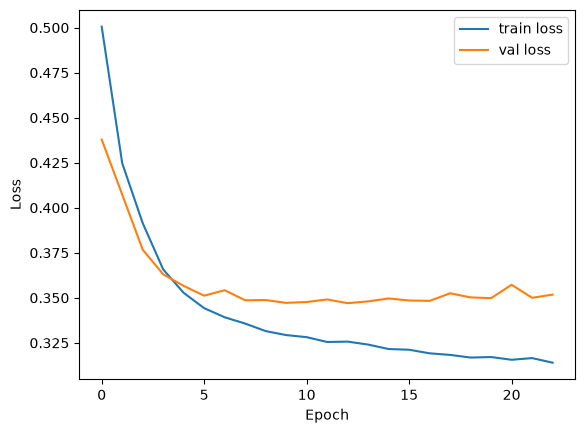

In [132]:
from tensorflow.keras.callbacks import EarlyStopping
es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(X_train_scaled, y_train, epochs=100, validation_split=0.2, callbacks=[es])


plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

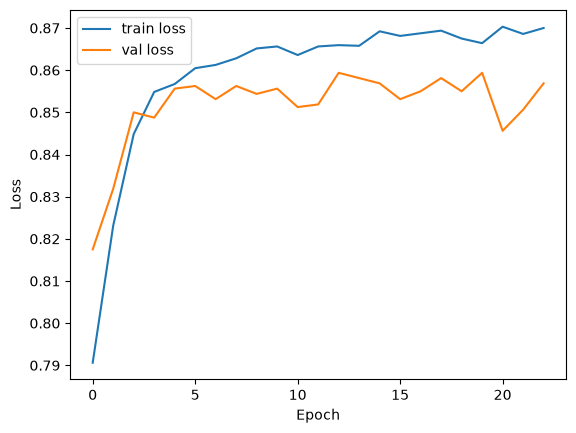

In [139]:
plt.plot(history.history['accuracy'], label='train loss')
plt.plot(history.history['val_accuracy'], label='val loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [133]:
model.layers[0].get_weights()

[array([[-6.24774881e-02,  5.87642901e-02,  2.87827570e-02,
          2.06953868e-01, -3.82649958e-01, -1.39897346e-01,
         -2.89837241e-01,  1.25816083e-02,  1.40148923e-01,
          9.87568423e-02,  3.24425310e-01, -1.76188350e-01,
          1.04802601e-01,  4.19623703e-02,  2.86858946e-01,
         -3.07490788e-02,  2.19334289e-01, -3.73716541e-02,
          8.16859081e-02, -3.06624055e-01,  1.98988672e-02,
          2.30973169e-01,  1.39748991e-01,  3.05245340e-01,
         -6.23827241e-02,  8.01216513e-02, -8.39535445e-02,
         -1.10995248e-01,  2.12914005e-01,  5.20730056e-02,
         -1.59237534e-01,  1.31619439e-01],
        [-2.57037252e-01,  2.78710961e-01,  1.27794102e-01,
         -1.15247652e-01, -1.70636833e-01,  5.18032074e-01,
         -2.80412321e-04, -1.35579541e-01,  5.12957014e-02,
          4.84223396e-01,  1.99026048e-01, -3.60558361e-01,
          7.88801759e-02,  7.88797736e-02,  4.60739359e-02,
          4.46552455e-01, -3.27826917e-01,  4.00710702e-

In [134]:
model.layers[1].get_weights()


[array([[-2.12123558e-01,  6.91044927e-02,  3.22449893e-01,
         -2.03526229e-01,  2.11430173e-02, -2.78026350e-02,
          3.67821269e-02,  1.71044003e-02,  3.61613721e-01,
          3.93100023e-01, -2.26673305e-01,  1.88575819e-01,
          2.50769615e-01,  1.90749213e-01, -2.60568857e-01,
         -3.03770285e-02],
        [ 1.41738862e-01,  1.65767789e-01,  6.23468645e-02,
         -1.49287358e-01,  2.42393330e-01,  2.93396711e-01,
         -2.03868270e-01, -4.62794214e-01, -4.04565036e-01,
         -3.13519575e-02, -4.48406219e-01,  2.41398960e-01,
          2.48085618e-01,  8.26848894e-02,  1.24432221e-01,
          3.46193105e-01],
        [ 4.18309450e-01, -2.74366140e-01,  2.46182859e-01,
         -2.86704212e-01, -1.03732921e-01,  3.52549583e-01,
         -1.39493018e-01, -1.51735559e-01,  2.59689957e-01,
         -5.38883172e-02, -2.00685069e-01,  2.21949294e-01,
          2.97076553e-01, -1.01196937e-01, -2.33781263e-02,
         -1.57770947e-01],
        [ 2.4281454

In [135]:
from sklearn.metrics import roc_auc_score, roc_curve

y_prob = model.predict(X_test_scaled).ravel()

fpr, tpr, threshold = roc_curve(y_test, y_prob)

best_idx = np.argmax(tpr - fpr)
best_threshold = threshold[best_idx]


print("Best threshold:", best_threshold)

y_pred = (y_prob >= best_threshold).astype(int)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
Best threshold: 0.27114546298980713


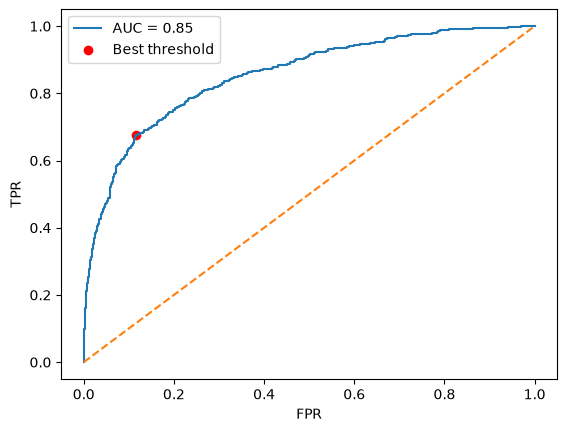

In [136]:
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.2f}")
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', label='Best threshold')
plt.plot([0, 1], [0, 1], '--')   # random guess line
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend()
plt.show()

In [137]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8425
[[1419  188]
 [ 127  266]]
              precision    recall  f1-score   support

           0       0.92      0.88      0.90      1607
           1       0.59      0.68      0.63       393

    accuracy                           0.84      2000
   macro avg       0.75      0.78      0.76      2000
weighted avg       0.85      0.84      0.85      2000

